<a href="https://colab.research.google.com/github/hibu24-blip/EES_322_lab2-spectral-indices-landsat8-/blob/main/EES_322_Lab2_Spectral_Indices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install -U geemap

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Packages imported successfully.")

Packages imported successfully.


In [4]:
PROJECT_ID="earth-science-project-505109"
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print("Earth Engine initialised.")

Earth Engine initialised.


In [6]:
CENTER_LON = 93.8385
CENTER_LAT = 27.595

centre = ee.Geometry.Point([CENTER_LON, CENTER_LAT])
aoi = centre.buffer(20_000).bounds()

print("AOI created.")

AOI created.


In [7]:
START_DATE = "2025-01-01"
END_DATE = "2025-12-31"
MAX_CLOUD = 60

raw_collection = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(aoi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD))
)

scene_count = raw_collection.size().getInfo()
print("Number of matching scenes:", scene_count)

if scene_count == 0:
    raise ValueError("No scenes found")

Number of matching scenes: 22


In [8]:
def preprocess_landsat8(image):
    qa = image.select("QA_PIXEL")

    # QA_PIXEL:
    # bit 1 = dilated cloud
    # bit 2 = cirrus
    # bit 3 = cloud
    # bit 4 = cloud shadow
    # bit 5 = snow

    clear_mask = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 2).eq(0))
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
        .And(qa.bitwiseAnd(1 << 5).eq(0))
    )

    saturation_mask = image.select("QA_RADSAT").eq(0)

    optical = (
        image.select("SR_B[1-7]")
        .multiply(0.0000275)
        .add(-0.2)
    )

    return (
        image.addBands(optical, None, True)
        .updateMask(clear_mask)
        .updateMask(saturation_mask)
    )


raw_image = ee.Image(raw_collection.sort("CLOUD_COVER").first())
image = preprocess_landsat8(raw_image)

print("Product ID:", raw_image.get("LANDSAT_PRODUCT_ID").getInfo())
print("Acquisition date:", raw_image.date().format("YYYY-MM-dd").getInfo())
print("Scene cloud cover (%):", raw_image.get("CLOUD_COVER").getInfo())

Product ID: LC08_L2SP_136041_20251218_20251225_02_T1
Acquisition date: 2025-12-18
Scene cloud cover (%): 1.54


In [9]:
# Select the reflectance bands once for clarity.

green = image.select("SR_B3")
red = image.select("SR_B4")
nir = image.select("SR_B5")
swir2 = image.select("SR_B7")


# NDVI
ndvi = image.expression(
    "(NIR - RED) / (NIR + RED)",
    {"NIR": nir, "RED": red}
).rename("NDVI")


# McFeeters NDWI
ndwi = image.expression(
    "(GREEN - NIR) / (GREEN + NIR)",
    {"GREEN": green, "NIR": nir}
).rename("NDWI")


# SAVI
L = 0.5

savi = image.expression(
    "((NIR - RED) / (NIR + RED + L)) * (1 + L)",
    {"NIR": nir, "RED": red, "L": L}
).rename("SAVI")


# NBR
nbr = image.expression(
    "(NIR - SWIR2) / (NIR + SWIR2)",
    {"NIR": nir, "SWIR2": swir2}
).rename("NBR")


index_image = image.addBands([ndvi, ndwi, savi, nbr])

print("Index bands added:")
print(index_image.bandNames().getInfo())

Index bands added:
['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'SR_QA_AEROSOL', 'ST_B10', 'ST_ATRAN', 'ST_CDIST', 'ST_DRAD', 'ST_EMIS', 'ST_EMSD', 'ST_QA', 'ST_TRAD', 'ST_URAD', 'QA_PIXEL', 'QA_RADSAT', 'NDVI', 'NDWI', 'SAVI', 'NBR']


In [10]:
Map = geemap.Map()
Map.centerObject(aoi, 10)

true_color = {
    "bands": ["SR_B4", "SR_B3", "SR_B2"],
    "min": 0.0,
    "max": 0.30,
}

false_color = {
    "bands": ["SR_B5", "SR_B4", "SR_B3"],
    "min": 0.0,
    "max": 0.35,
}

Map.addLayer(image.clip(aoi), true_color, "True colour (4-3-2)", True)

Map.addLayer(image.clip(aoi), false_color, "False colour (5-4-3)", False)

Map.addLayer(
    ndvi.clip(aoi),
    {"min": -1, "max": 1, "palette": ["8c510a", "f6e8c3", "01665e"]},
    "NDVI",
    False
)

Map.addLayer(
    ndwi.clip(aoi),
    {"min": -1, "max": 1, "palette": ["a6611a", "f5f5f5", "018571"]},
    "NDWI (McFeeters)",
    False
)

Map.addLayer(
    savi.clip(aoi),
    {"min": -1, "max": 1, "palette": ["8c510a", "f6e8c3", "01665e"]},
    "SAVI",
    False
)

Map.addLayer(
    nbr.clip(aoi),
    {"min": -1, "max": 1, "palette": ["b2182b", "f7f7f7", "2166ac"]},
    "NBR",
    False
)

Map.addLayer(aoi, {"color": "black"}, "AOI", False)

Map

Map(center=[27.594984668878382, 93.83885730214234], controls=(WidgetControl(options=['position', 'transparent_…

In [11]:
indices = index_image.select(["NDVI", "NDWI", "SAVI", "NBR"])

stats = indices.reduceRegion(
    reducer=(
        ee.Reducer.mean()
        .combine(ee.Reducer.stdDev(), sharedInputs=True)
        .combine(ee.Reducer.minMax(), sharedInputs=True)
    ),
    geometry=aoi,
    scale=30,
    maxPixels=1e8,
    bestEffort=True,
)

stats_dict = stats.getInfo()

summary_rows = []

for name in ["NDVI", "NDWI", "SAVI", "NBR"]:
    summary_rows.append({
        "Index": name,
        "Mean": stats_dict.get(f"{name}_mean"),
        "StdDev": stats_dict.get(f"{name}_stdDev"),
        "Min": stats_dict.get(f"{name}_min"),
        "Max": stats_dict.get(f"{name}_max"),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Index,Mean,StdDev,Min,Max
0,NDVI,0.834773,0.118262,-1.741836,2.045794
1,NDWI,-0.797571,0.094615,-2.988984,1.158734
2,SAVI,0.375149,0.141839,-0.168687,0.816359
3,NBR,0.653030,0.149544,-2.571831,1.022921


In [12]:
sample_fc = indices.sample(
    region=aoi,
    scale=30,
    numPixels=2500,
    seed=42,
    geometries=False,
    tileScale=2,
)

sample_info = sample_fc.getInfo()

sample_df = pd.DataFrame(
    [feature["properties"] for feature in sample_info["features"]]
).dropna()

print("Number of sampled clear pixels:", len(sample_df))
sample_df.head()

Number of sampled clear pixels: 2182


,NBR,NDVI,NDWI,SAVI
0,0.620018,0.814769,-0.782010,0.403924
1,0.765904,0.909801,-0.865596,0.545646
2,0.666077,0.863990,-0.808508,0.305443
3,-0.106165,0.145257,-0.231795,0.082869
4,0.671511,0.894423,-0.853080,0.474542


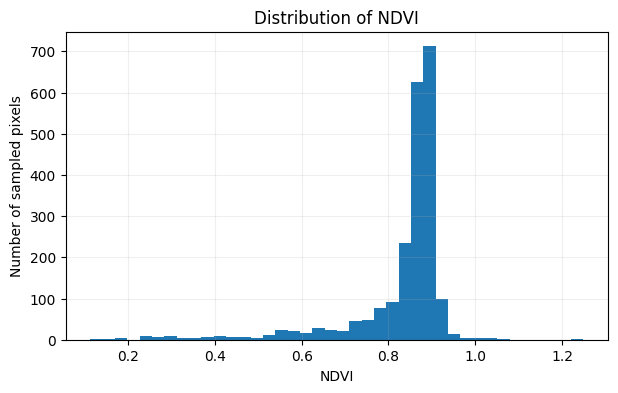

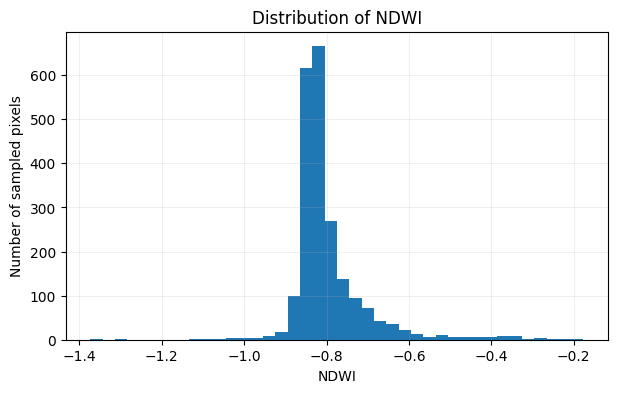

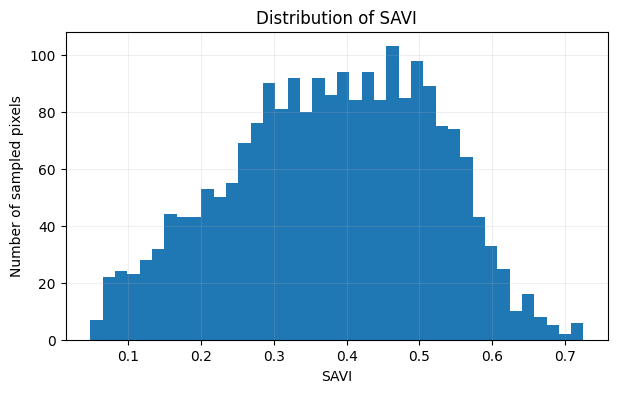

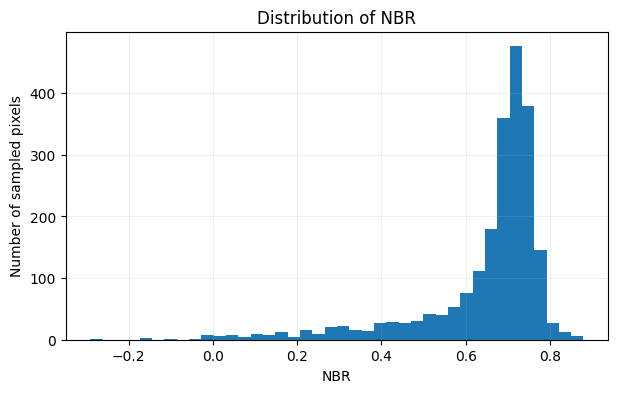

In [13]:
# Plot a separate histogram for each index.

for name in ["NDVI", "NDWI", "SAVI", "NBR"]:
    plt.figure(figsize=(7, 4))
    plt.hist(sample_df[name], bins=40)
    plt.xlabel(name)
    plt.ylabel("Number of sampled pixels")
    plt.title(f"Distribution of {name}")
    plt.grid(alpha=0.2)
    plt.show()

In [14]:
# Compare NDVI and SAVI numerically.

sample_df["NDVI_minus_SAVI"] = sample_df["NDVI"] - sample_df["SAVI"]

comparison = sample_df[["NDVI", "SAVI", "NDVI_minus_SAVI"]].describe()

comparison

,NDVI,SAVI,NDVI_minus_SAVI
count,2182.000000,2182.000000,2182.000000
mean,0.831591,0.378978,0.452613
std,0.119829,0.139503,0.157059
min,0.112941,0.047738,0.055049
25%,0.834990,0.280371,0.338573
50%,0.871508,0.386896,0.434318
75%,0.888766,0.489152,0.557816
max,1.249674,0.725636,1.193806


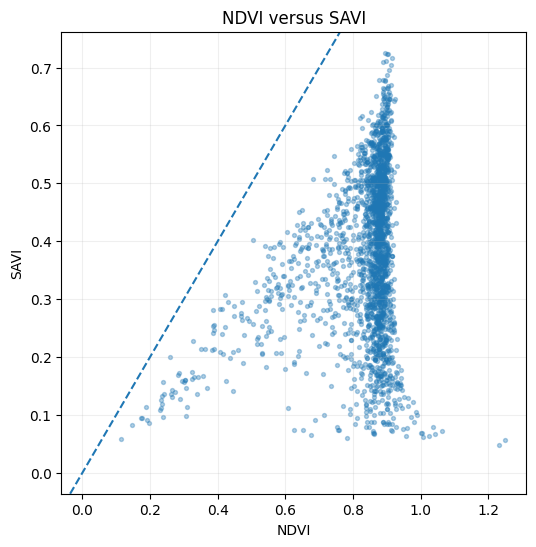

In [15]:
plt.figure(figsize=(6, 6))

plt.scatter(sample_df["NDVI"], sample_df["SAVI"], s=8, alpha=0.35)

plt.xlabel("NDVI")
plt.ylabel("SAVI")
plt.title("NDVI versus SAVI")
plt.axline((0, 0), slope=1, linestyle="--")
plt.grid(alpha=0.2)
plt.show()

In [16]:
vegetation_candidate = ndvi.gt(0.40).rename("Vegetation_candidate")
water_candidate = ndwi.gt(0.00).rename("Water_candidate")

MaskMap = geemap.Map()
MaskMap.centerObject(aoi, 10)

MaskMap.addLayer(image.clip(aoi), true_color, "True colour", True)

MaskMap.addLayer(
    vegetation_candidate.selfMask().clip(aoi),
    {"palette": ["00AA00"]},
    "NDVI > 0.40",
    False,
)

MaskMap.addLayer(
    water_candidate.selfMask().clip(aoi),
    {"palette": ["0000FF"]},
    "NDWI > 0",
    False,
)

MaskMap

Map(center=[27.594984668878357, 93.83885730214234], controls=(WidgetControl(options=['position', 'transparent_…

In [17]:
export_indices = index_image.select(
    ["NDVI", "NDWI", "SAVI", "NBR"]
).clip(aoi)

task = ee.batch.Export.image.toDrive(
    image=export_indices,
    description="Landsat8_Spectral_Indices",
    folder="EarthEngine",
    fileNamePrefix="Landsat8_NDVI_NDWI_SAVI_NBR",
    region=aoi,
    scale=30,
    maxPixels=1e9,
    fileFormat="GeoTIFF",
)

# task.start()

print("Export prepared. Uncomment task.start() to submit it.")

Export prepared. Uncomment task.start() to submit it.
